# 2. Target, features and pipeline studies (Stages 4, 5, 7)

Outputs come from `python -m src.dataset` and `python -m src.studies`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 160)

def show(name):
    display(Image(f"../reports/figures/{name}.png"))

def table(name):
    return pd.read_csv(f"../reports/tables/{name}.csv")

In [2]:
from src.dataset import FEATURES, load
data = load()
print(len(data), "rows,", len(FEATURES), "features")
data.groupby("split").size()

809660 rows, 20 features


split
test     366110
train    260819
val      182731
dtype: int64

## Target (B1)
Health(t) = actual power / (irradiance x kWp x 0.78) x 100, limited to 0-100.
The model predicts **Health one hour later**, so it never learns the formula back (section 7.2, Option A).
Status: Healthy >= 90, Warning 70-90, Faulty < 70.

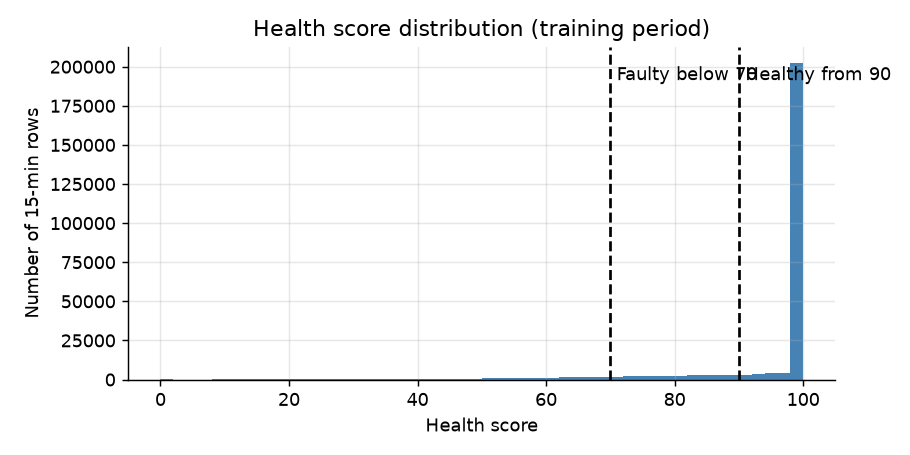

,faulty_below,healthy_from,faulty_pct,warning_pct,healthy_pct
0,60,85,4.4,9.6,86.0
1,60,90,4.4,12.4,83.2
2,60,95,4.4,15.6,80.0
3,65,85,5.7,8.3,86.0
4,65,90,5.7,11.1,83.2
5,65,95,5.7,14.3,80.0
6,70,85,7.3,6.7,86.0
7,70,90,7.3,9.5,83.2
8,70,95,7.3,12.7,80.0
9,75,85,9.2,4.8,86.0


In [3]:
show("target_health_distribution")
table("study_thresholds")

**Finding.** With Faulty < 70 and Healthy >= 90, the training rows are 7.3 % Faulty, 9.5 % Warning and 83.2 % Healthy. Moving the Faulty cut from 60 to 80 changes the Faulty share from 4.4 % to 11.4 %. 70 / 90 keep the Faulty class large enough to learn while still meaning clearly below expected.

## Features (all four members)

In [4]:
pd.DataFrame({"feature": FEATURES})

,feature
0,health_now
1,n_valid_5min
2,minutes_offline_24h
3,irradiance_wm2
4,temp_c
5,rh_pct
6,wind_speed_ms
7,hour_sin
8,hour_cos
9,day_sin


Every feature is known at time t: current state and outages (A1), weather, time and metadata (B2), peer and self deviation (B1), recent history (A2). Rolling windows exclude the current row, so nothing from the future leaks in.

## Stage 7: feature selection - nearly identical features

In [5]:
table("study_correlated_features")

,feature_1,feature_2,correlation
0,tilt_deg,multi_orientation,0.974


**Decision:** `multi_orientation` is dropped; the other 20 features stay.

## Stage 4: imputation choice (A2)

In [6]:
table("study_imputation")

,imputation,rmse,mae,r2
0,median,10.68,6.004,0.649
1,mean,10.67,6.025,0.650


**Finding.** Median and mean filling give the same validation RMSE (10.79 vs 10.78). **Decision:** median, which is robust to outliers.

## Stage 5: class balancing (A2)

In [7]:
table("study_balancing")

,strategy,train_rows,macro_f1,faulty_recall,faulty_precision
0,no balancing,260819,0.547,0.595,0.745
1,balanced class weights,260819,0.574,0.724,0.471
2,undersample Healthy (2 per other),116940,0.605,0.655,0.619


**Finding.** Balanced class weights give the highest Faulty recall (0.72 vs 0.59 without balancing) and keep every training row. **Decision:** every classifier is trained with balanced sample weights. SMOTE was not used: it invents rows by mixing neighbours, which does not suit time series.